In [1]:
import sklearn
import numpy as np
import pandas as pd

Se carga el archivo y se separa en entrenamiento y prueba

In [2]:
from sklearn.model_selection import train_test_split
dataALL=pd.read_csv('data/tuberculosis.csv')
N=len(dataALL)
cTrain=int(N*0.8) # 80% para entrenar y 20% para probar
cTest=N-cTrain
print(N,cTrain,cTest)
train_data,test_data= sklearn.model_selection.train_test_split(dataALL, train_size=cTrain, test_size=cTest)

1455 1164 291


In [3]:
train_data.shape

(1164, 15)

In [4]:
train_data.head()

,SEXO,EDAD,ETNIA,GRUPOPOBLACIONAL,COMORBILIDAD,MALNUTRICION,Contactos,ContactosSR,ContactosSRExaminadosconBK,ContactosMenores5Anios,VIHCONFIRMADO,RECIBETAR,RECIBETRIMETOPRIN,RDOBKDX,TUBERCULOSIS
1185,1,30.0,2,3,5,0,11,11,11,0,2,2,2,5,1
811,0,44.0,2,4,5,0,5,0,0,2,2,2,2,4,1
234,1,47.0,2,4,5,0,1,0,0,0,2,2,2,4,0
201,1,83.0,2,4,3,0,0,0,0,0,0,2,2,4,0
329,0,30.0,2,4,5,1,2,0,0,0,2,2,2,2,0


In [5]:
train_data.info()

<class 'pandas.core.frame.DataFrame'>
Index: 1164 entries, 1185 to 1322
Data columns (total 15 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   SEXO                        1164 non-null   int64  
 1   EDAD                        1164 non-null   float64
 2   ETNIA                       1164 non-null   int64  
 3   GRUPOPOBLACIONAL            1164 non-null   int64  
 4   COMORBILIDAD                1164 non-null   int64  
 5   MALNUTRICION                1164 non-null   int64  
 6   Contactos                   1164 non-null   int64  
 7   ContactosSR                 1164 non-null   int64  
 8   ContactosSRExaminadosconBK  1164 non-null   int64  
 9   ContactosMenores5Anios      1164 non-null   int64  
 10  VIHCONFIRMADO               1164 non-null   int64  
 11  RECIBETAR                   1164 non-null   int64  
 12  RECIBETRIMETOPRIN           1164 non-null   int64  
 13  RDOBKDX                     1164 no

In [6]:
train_data[["EDAD", "MALNUTRICION","Contactos","RECIBETRIMETOPRIN"]].describe()

,EDAD,MALNUTRICION,Contactos,RECIBETRIMETOPRIN
count,1164.000000,1164.000000,1164.000000,1164.000000
mean,40.540378,0.052405,2.845361,1.914089
std,19.920934,0.222939,5.880887,0.333574
min,1.000000,0.000000,0.000000,0.000000
25%,25.000000,0.000000,0.000000,2.000000
50%,34.000000,0.000000,2.000000,2.000000
75%,57.000000,0.000000,4.000000,2.000000
max,95.000000,1.000000,111.000000,2.000000


### Pipeline para los atributos numéricos

In [7]:
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.preprocessing import MinMaxScaler

# 14 atributos numéricos
num_attribs = ["SEXO", "EDAD", "ETNIA", "GRUPOPOBLACIONAL","COMORBILIDAD","MALNUTRICION","Contactos","ContactosSR","ContactosSRExaminadosconBK","ContactosMenores5Anios","VIHCONFIRMADO","RECIBETAR","RECIBETRIMETOPRIN","RDOBKDX"]

num_pipeline = Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler())

    ])

### Pipeline completo

In [8]:
from sklearn.compose import ColumnTransformer

full_pipeline = ColumnTransformer([
    ("num", num_pipeline, num_attribs),
])

### Extraemos las etiquetas de clase

In [9]:
X_train = full_pipeline.fit_transform(train_data)

In [10]:
X_train.shape

(1164, 14)

In [11]:
X_train[0,:]

array([ 0.6934811 , -0.52933807,  0.38916384, -0.65732716,  0.35133075,
       -0.23516742,  1.38723015,  1.68949059,  1.78358097, -0.2584827 ,
        0.30072674,  0.25821323,  0.25765666,  1.06978364])

In [12]:
y_train = train_data["TUBERCULOSIS"]
y_train

1185    1
811     1
234     0
201     0
329     0
       ..
1188    1
258     0
700     1
1035    1
1322    1
Name: TUBERCULOSIS, Length: 1164, dtype: int64

# Árboles de decisión
## Algoritmo DecisionTreeClassifier

[0.7167382  0.68669528 0.70386266 0.69098712 0.68534483]
0.6967256178777564


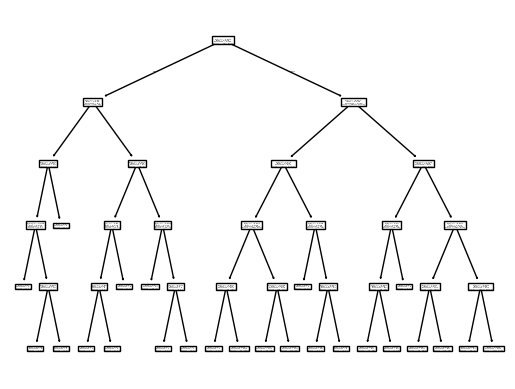

In [13]:
from sklearn import tree
from sklearn.model_selection import cross_val_score

modelo1= tree.DecisionTreeClassifier(criterion='gini',max_depth=5,splitter="best",random_state=123)
modelo1.fit(X_train, y_train)
scores1 = cross_val_score(modelo1, X_train, y_train, cv=5,scoring='accuracy')
print(scores1)
print(scores1.mean())

tree.plot_tree(modelo1)
tree.export_graphviz(decision_tree=modelo1, class_names=True,out_file="Arbol Tuberculosis 1.dot")

# Modificando los hiperparámetros

[0.58369099 0.60944206 0.63090129 0.63090129 0.66810345]
0.6246078141186918


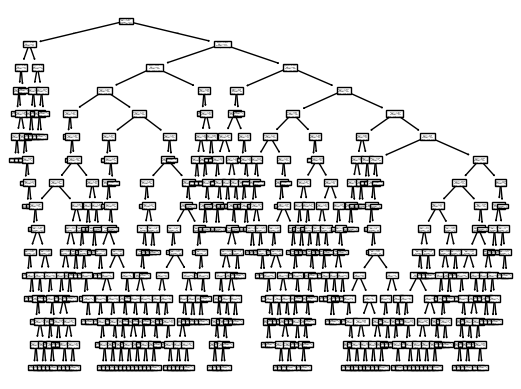

In [14]:
from sklearn import tree
from sklearn.model_selection import cross_val_score

modelo2 = tree.DecisionTreeClassifier(criterion='gini',max_depth=15,splitter="best",random_state=123)
modelo2.fit(X_train, y_train)
scores2 = cross_val_score(modelo2, X_train, y_train, cv=5, scoring='accuracy')
print(scores2)
print(scores2.mean())

tree.plot_tree(modelo2)
tree.export_graphviz(decision_tree=modelo2, class_names=True,out_file="Arbol Tuberculosis 2.dot")

# Analicemos el desempeño en el conjunto de prueba

In [15]:
X_test = full_pipeline.transform(test_data)
X_test

array([[ 0.6934811 , -1.03153834,  0.38916384, ...,  0.25821323,
         0.25765666, -1.65898515],
       [ 0.6934811 , -0.67999815,  0.38916384, ...,  0.25821323,
         0.25765666,  0.16019404],
       [-1.44200037, -0.98131832,  0.38916384, ...,  0.25821323,
         0.25765666,  0.16019404],
       ...,
       [ 0.6934811 , -0.62977813,  0.38916384, ...,  0.25821323,
         0.25765666,  1.06978364],
       [-1.44200037,  0.17374231,  0.38916384, ..., -2.80872758,
        -2.7414669 ,  1.06978364],
       [ 0.6934811 ,  1.42924299,  0.38916384, ...,  0.25821323,
         0.25765666,  1.06978364]], shape=(291, 14))

In [16]:
y_pred1 = modelo1.predict(X_test)
y_pred1

array([1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 0, 1, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 0, 0, 1, 1, 1, 1, 1,
       0, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
       1, 0, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 0, 1, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 0, 1, 1, 1, 0, 1, 0, 1, 1, 1, 0, 1,
       1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 0, 1, 1, 1, 0,
       1, 1, 1, 1, 1, 1, 1, 1, 1, 0, 1, 1, 1, 1, 1, 0, 1, 1, 1, 1, 1, 1,
       0, 0, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 0, 1, 1, 1, 1, 1, 1,
       1, 0, 1, 1, 1, 1, 1, 1, 1, 1, 0, 1, 1, 1, 1, 0, 1, 1, 1, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 0, 1, 1, 1, 1, 1, 0, 1, 1, 0,
       1, 1, 1, 1, 1])

In [17]:
y_pred2 = modelo2.predict(X_test)
y_pred2

array([1, 0, 0, 1, 1, 1, 0, 1, 1, 1, 0, 0, 1, 1, 1, 1, 1, 0, 0, 1, 1, 1,
       1, 1, 1, 1, 0, 1, 1, 1, 1, 0, 1, 1, 1, 0, 1, 0, 1, 1, 1, 1, 1, 1,
       1, 1, 0, 1, 0, 1, 1, 1, 1, 1, 0, 1, 0, 0, 1, 0, 0, 1, 1, 1, 0, 1,
       0, 1, 1, 0, 1, 1, 0, 0, 1, 1, 1, 0, 1, 1, 1, 1, 1, 0, 1, 1, 1, 1,
       0, 0, 1, 1, 1, 1, 1, 1, 1, 1, 1, 0, 1, 0, 1, 1, 0, 0, 1, 1, 1, 0,
       0, 1, 1, 1, 0, 1, 1, 1, 0, 1, 1, 0, 1, 0, 1, 1, 1, 1, 0, 1, 1, 0,
       0, 1, 1, 0, 1, 1, 1, 1, 0, 0, 1, 1, 0, 1, 0, 1, 0, 1, 0, 1, 0, 1,
       1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 0, 1, 1, 1, 1, 0, 0, 0, 0, 1, 0,
       0, 1, 1, 0, 1, 1, 1, 0, 1, 0, 1, 1, 1, 1, 1, 0, 1, 1, 1, 0, 1, 1,
       0, 0, 1, 1, 1, 1, 1, 1, 1, 0, 1, 1, 1, 1, 1, 0, 1, 1, 1, 1, 1, 0,
       1, 1, 1, 1, 0, 1, 0, 1, 1, 1, 1, 1, 0, 1, 1, 0, 1, 0, 1, 0, 1, 0,
       1, 1, 1, 0, 1, 1, 1, 1, 0, 1, 1, 1, 1, 0, 1, 1, 1, 1, 0, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 0, 1, 1, 1, 1, 0, 1, 1, 0, 0, 1, 0,
       0, 1, 0, 0, 1])

In [18]:
y_test = test_data["TUBERCULOSIS"]

In [19]:
y_test

607     1
785     1
724     1
714     1
424     0
       ..
627     1
273     0
1070    1
1007    1
1109    1
Name: TUBERCULOSIS, Length: 291, dtype: int64

In [20]:
from sklearn.metrics import accuracy_score
accuracy_score(y_test, y_pred1)

0.697594501718213

In [21]:
from sklearn.metrics import confusion_matrix
confusion_matrix1 = confusion_matrix(y_test, y_pred1)
confusion_matrix1

array([[ 10,  75],
       [ 13, 193]])

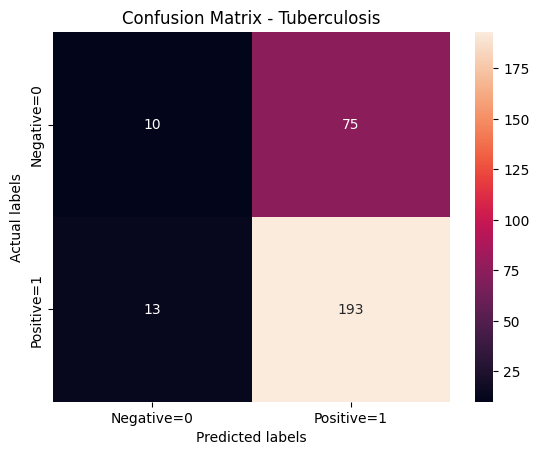

In [23]:
%matplotlib inline
import matplotlib.pyplot as plt
import seaborn as sns

ax = plt.subplot()
sns.heatmap(confusion_matrix1, annot=True, ax = ax, fmt='d')

ax.set_xlabel('Predicted labels')
ax.set_ylabel('Actual labels')
ax.set_title('Confusion Matrix - Tuberculosis')
ax.xaxis.set_ticklabels(['Negative=0', 'Positive=1'])
ax.yaxis.set_ticklabels(['Negative=0', 'Positive=1']);
plt.show();

In [ ]:
from sklearn.metrics import accuracy_score
accuracy_score(y_test, y_pred2)

0.5807560137457045

In [ ]:
from sklearn.metrics import confusion_matrix
confusion_matrix2 = confusion_matrix(y_test, y_pred2)
confusion_matrix2

array([[ 20,  73],
       [ 49, 149]])

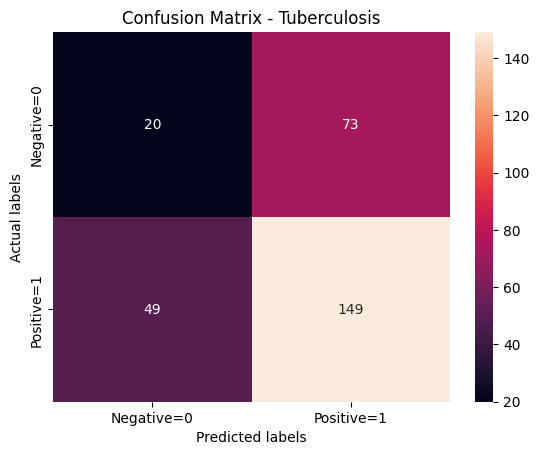

In [ ]:
%matplotlib inline
import matplotlib.pyplot as plt
import seaborn as sns

ax = plt.subplot()
sns.heatmap(confusion_matrix2, annot=True, ax = ax, fmt='d')

ax.set_xlabel('Predicted labels')
ax.set_ylabel('Actual labels')
ax.set_title('Confusion Matrix - Tuberculosis')
ax.xaxis.set_ticklabels(['Negative=0', 'Positive=1'])
ax.yaxis.set_ticklabels(['Negative=0', 'Positive=1']);
plt.show();